In [29]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (Flatten, Dense, BatchNormalization, Dropout,Conv2D, MaxPooling2D)
from tensorflow.keras.callbacks import EarlyStopping,ModelCheckpoint


In [5]:
dataset_path= r'c:\Users\DELL1\Downloads\archive (9)\Vegetable Images'
train_path=os.path.join(dataset_path,'train')
validation_path=os.path.join(dataset_path,'validation')
test_path=os.path.join(dataset_path,'test')
print(os.listdir(dataset_path))

['test', 'train', 'validation']


In [7]:
class_names=os.listdir(train_path)
print(class_names)
print(len(class_names))

['Bean', 'Bitter_Gourd', 'Bottle_Gourd', 'Brinjal', 'Broccoli', 'Cabbage', 'Capsicum', 'Carrot', 'Cauliflower', 'Cucumber', 'Papaya', 'Potato', 'Pumpkin', 'Radish', 'Tomato']
15


In [9]:
for class_name in class_names:
    class_path=os.path.join(train_path,class_name)
    images=os.listdir(class_path)
    print(class_name,len(images))

Bean 1000
Bitter_Gourd 1000
Bottle_Gourd 1000
Brinjal 1000
Broccoli 1000
Cabbage 1000
Capsicum 1000
Carrot 1000
Cauliflower 1000
Cucumber 1000
Papaya 1000
Potato 1000
Pumpkin 1000
Radish 1000
Tomato 1000


In [10]:
for folder_name in ['test', 'train', 'validation']:
    folder_path=os.path.join(dataset_path,folder_name)
    total_images=0
    for class_name in os.listdir(folder_path):
        class_path=os.path.join(folder_path,class_name)
        total_images=total_images+len(os.listdir(class_path))
    print(folder_name,total_images)

test 3000
train 15000
validation 3000


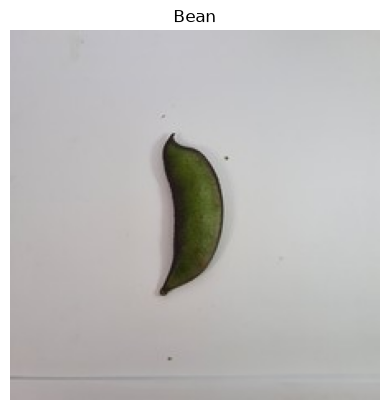

In [13]:
class_name=class_names[0]
class_path=os.path.join(train_path,class_name)
images=os.listdir(class_path)
image_path=os.path.join(class_path,images[0])
img=Image.open(image_path)
plt.imshow(img)
plt.title(class_name)
plt.axis('off')
plt.show()

In [14]:
img.size

(224, 224)

In [21]:
train_data=ImageDataGenerator(rescale=1./255,rotation_range=20,zoom_range=.2,horizontal_flip=True)
validation_data=ImageDataGenerator(rescale=1./255)
test_data=ImageDataGenerator(rescale=1./255)

In [23]:
Train_Data=train_data.flow_from_directory(train_path,target_size=(224,224),batch_size=30,class_mode='categorical',shuffle=True)
Validation_Data=validation_data.flow_from_directory(validation_path,target_size=(224,224),batch_size=30,class_mode='categorical',shuffle=False)
Test_Data=test_data.flow_from_directory(test_path,target_size=(224,224),batch_size=32,class_mode='categorical',shuffle=False)

Found 15000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.


In [25]:
print(Train_Data.class_indices)

{'Bean': 0, 'Bitter_Gourd': 1, 'Bottle_Gourd': 2, 'Brinjal': 3, 'Broccoli': 4, 'Cabbage': 5, 'Capsicum': 6, 'Carrot': 7, 'Cauliflower': 8, 'Cucumber': 9, 'Papaya': 10, 'Potato': 11, 'Pumpkin': 12, 'Radish': 13, 'Tomato': 14}


In [30]:
model=Sequential()
model.add(Conv2D(32,(3,3),activation='relu',input_shape=(224,224,3)))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(128,(3,3),activation='relu'))
model.add(MaxPooling2D((2,2)))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dropout(.4))

model.add(Dense(15,activation='softmax'))
model.summary()


c:\Users\DELL1\anaconda3\envs\alpha-python\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,170,895 (42.61 MB)

 Trainable params: 11,170,895 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [32]:
model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [33]:
early_stop=EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True)

In [34]:
checkPoin=ModelCheckpoint('Vegetable_cnn.keras',monitor='val_loss',save_best_only=True)

In [35]:
history=model.fit(Train_Data,validation_data=Validation_Data,epochs=2,callbacks=[early_stop,checkPoin])

Epoch 1/2
500/500 ━━━━━━━━━━━━━━━━━━━━ 634s 1s/step - accuracy: 0.5279 - loss: 1.4295 - val_accuracy: 0.8140 - val_loss: 0.6316
Epoch 2/2
500/500 ━━━━━━━━━━━━━━━━━━━━ 409s 818ms/step - accuracy: 0.7569 - loss: 0.7568 - val_accuracy: 0.8783 - val_loss: 0.3949


In [36]:
test_loss,test_accuracy=model.evaluate(Test_Data)
print('test loss',test_loss)
print('test accuracy',test_accuracy)


94/94 ━━━━━━━━━━━━━━━━━━━━ 32s 339ms/step - accuracy: 0.8743 - loss: 0.4145
test loss 0.41447579860687256
test accuracy 0.8743333220481873


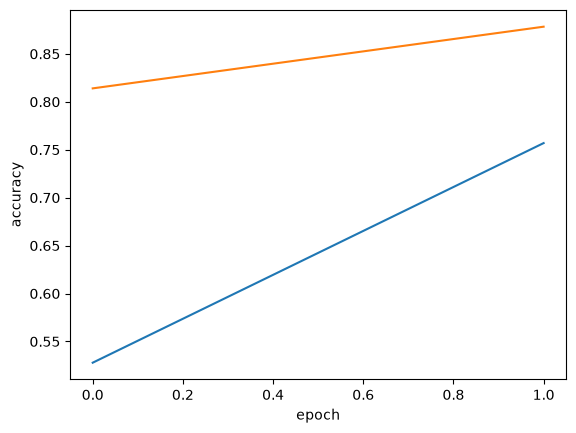

In [38]:
plt.plot(history.history['accuracy'],label='train accuracy')
plt.plot(history.history['val_accuracy'],label='validation accuracy')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.show()

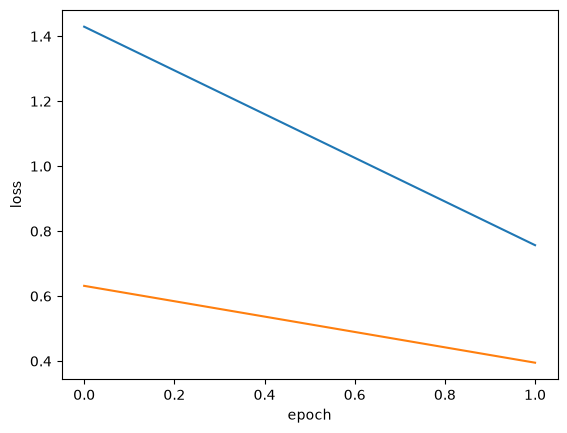

In [39]:
plt.plot(history.history['loss'],label='train loss')
plt.plot(history.history['val_loss'],label='validation loss')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

In [40]:
import json
class_names=list(Train_Data.class_indices.keys())
with open('class_names.json','w')as file:
    json.dump(class_names,file)